## Author: Gabriel Vance

## Class: DSC640 - Data Presentation & Visualization

## Professor: Benjamin Schneider

## Date: November 15, 2025

# Purpose: This notebook performs the tasks outlined in Week 9 & 10 Assignment - TSA Complaints. For this exercise we will be utilizing python/notebooks to visualize datasets pertaining to TSA complaints.


Medium: PDF report prepared for the White House Press Secretary  
Audience: This report will support the White House Press Secretary in communicating national trends in TSA complaints.  
Call to Action: Post-pandemic TSA complaints have risen above pre-pandemic levels. The administration acknowledges this increase and is taking proactive measures to enhance customer satisfaction and create a more accommodating travel experience.

In the years leading up to the pandemic, nationwide complaints generally ranged from **6,000 to 11,000 per year**. While this level was not ideal, it represented a relatively stable baseline.

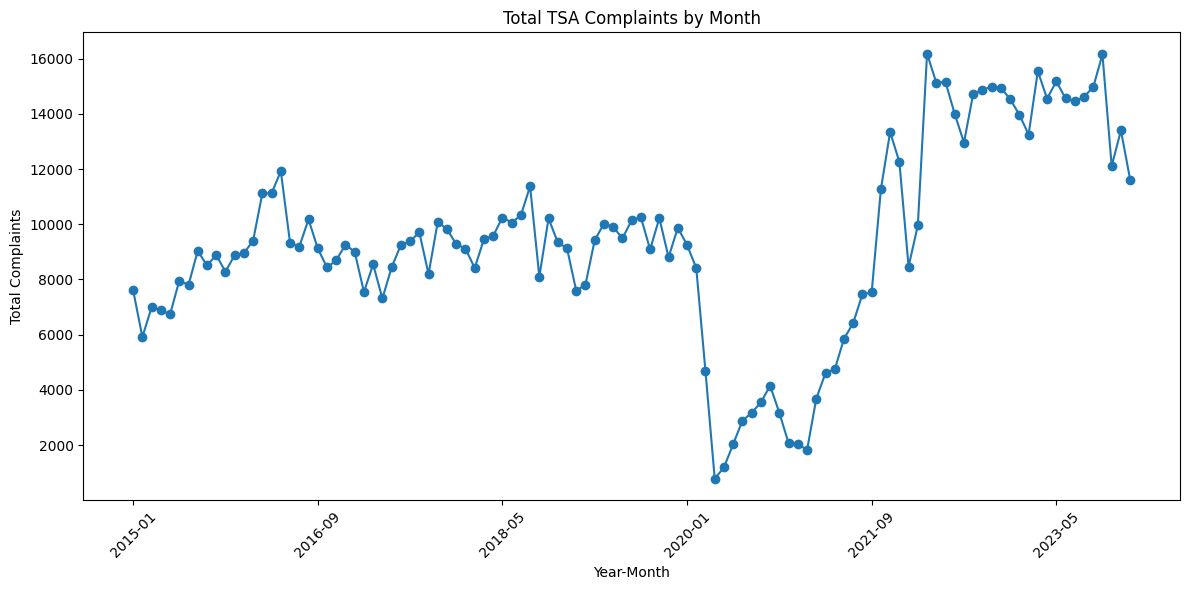

The significant decline in 2020 is directly attributable to the reduction in air travel during the pandemic. As travel volumes recovered, annual complaints increased substantially. Today, the new baseline appears to be between **13,000 and 15,000 complaints**, a level the administration considers unacceptable. A notable proportion of these complaints originate from the **Expedited Passenger Screening Program**, indicating a clear area requiring improvement.

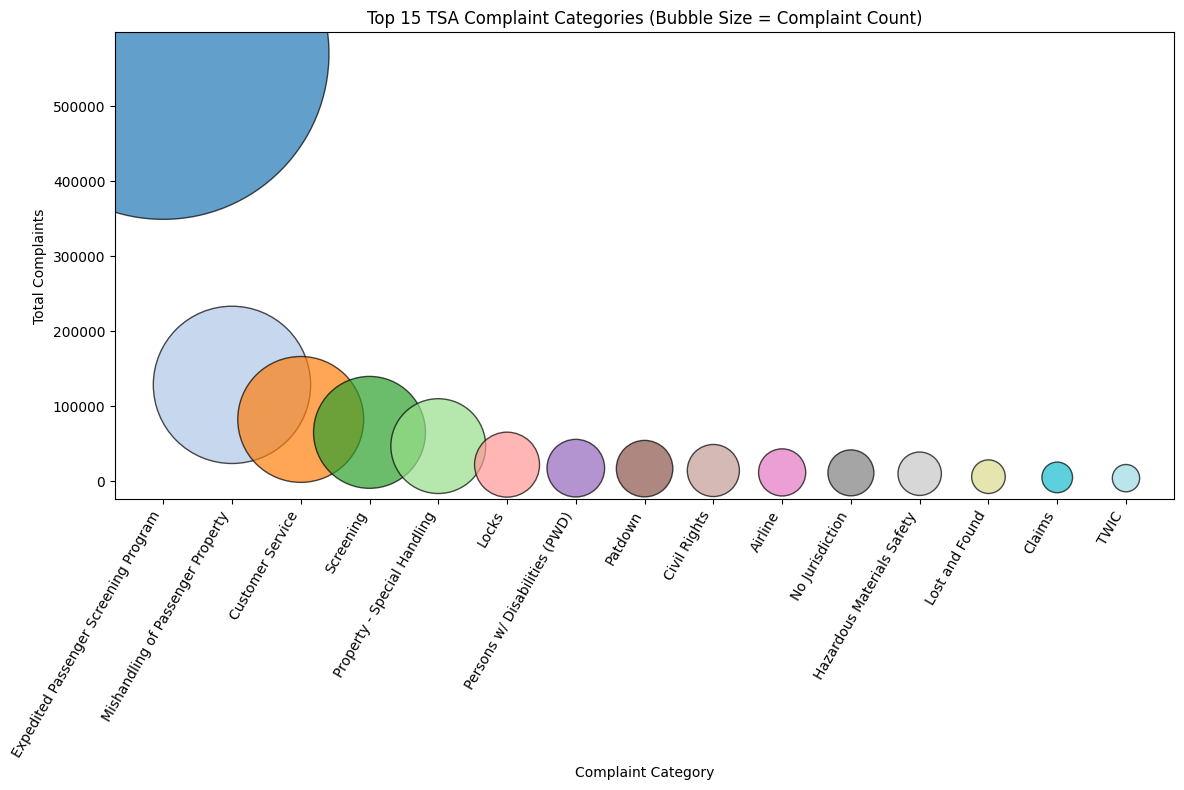

An analysis of the airports with the highest number of complaints shows **no consistent geographic pattern**. The top airports are distributed across multiple regions, suggesting that elevated complaint levels stem from broader systemic issues rather than location-specific factors.

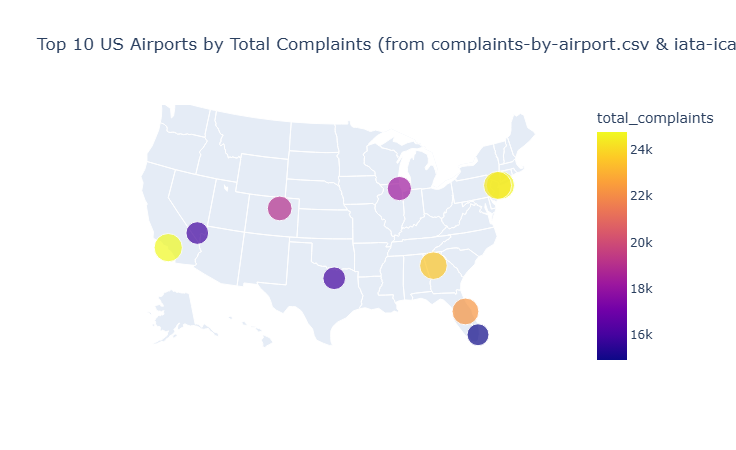

We are also tracking the airports with the highest number of complaints. We will be sending our professionals to these airports and conducting remedial training for TSA agents immediately.

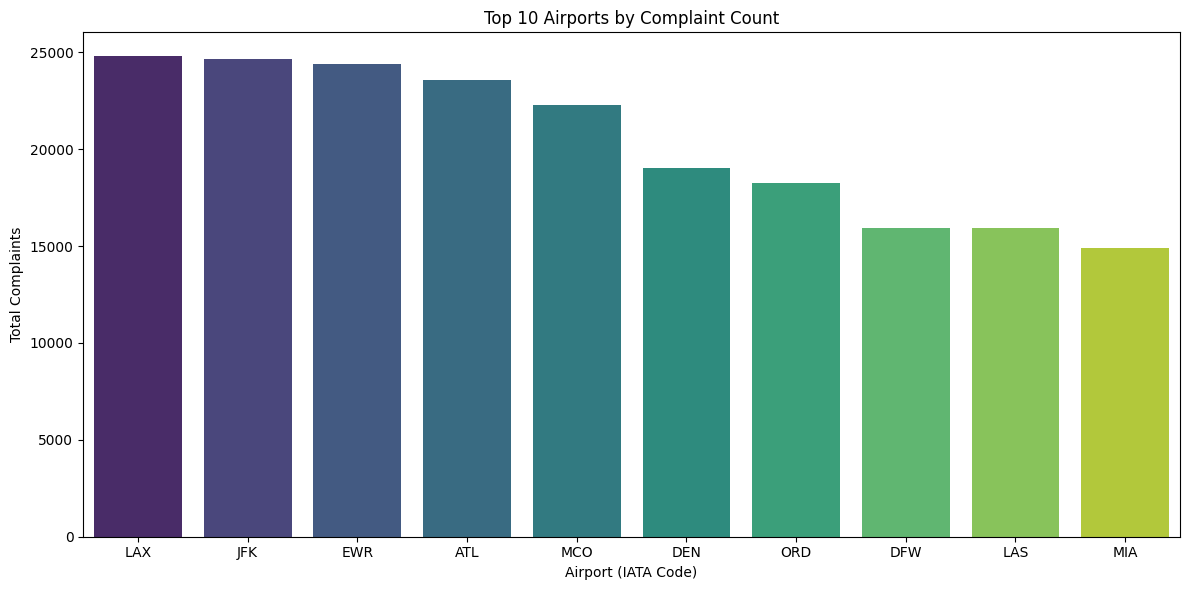

In conclusion, we are closely monitoring the post-pandemic increase in travel-related complaints. By prioritizing improvements within the highest-volume complaint categories and focusing on the airports with the greatest impact, we are confident that we can reduce complaint levels and significantly enhance the overall traveler experience. We will deliver an update in 6 months to report our results. Thank you.


# Code


In [18]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from matplotlib import MatplotlibDeprecationWarning
import plotly.express as px

# Jupyter display tweaks
# Suppress warnings for cleaner output
import os

# Suppress DeprecationWarning and TqdmWarning specifically
warnings.filterwarnings("ignore", category=DeprecationWarning)
os.environ["TQDM_DISABLE"] = "1"


from IPython.core.display import display, HTML

display(HTML("<style>.container { width:100% !important; }</style>"))
# Ensure that all code cells are fully visible without scrolling


warnings.filterwarnings("ignore", category=MatplotlibDeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

#### First we will read in data


In [19]:
iata_icao = pd.read_csv("iata-icao.csv")
complaints_by_subcategory = pd.read_csv("complaints-by-subcategory.csv")
iata_complaints_by_category_icao = pd.read_csv("complaints-by-category.csv")
complaints_by_airport = pd.read_csv("complaints-by-airport.csv")

## Visualization 1 – Spatial / Choropleth Map

- **Data Sources:** `complaints-by-airport.csv`, `iata-icao.csv`
- **Goal:** Plot the top 10 airports by total complaint count as geospatial map points.


In [20]:
# Aggregate complaints per airport
complaints_airport_totals = (
    complaints_by_airport.groupby("airport", as_index=False)["count"]
    .sum()
    .rename(columns={"count": "total_complaints"})
)

# Join with location data
airports_with_complaints = complaints_airport_totals.merge(
    iata_icao,
    left_on="airport",  # IATA code from complaints
    right_on="iata",  # IATA from iata_icao
    how="left",
)


# Keep only US airports and valid coordinates
us_airports = airports_with_complaints[
    airports_with_complaints["country_code"] == "US"
].dropna(subset=["latitude", "longitude"])

# Find top 10 airports by complaints
us_top_airports = us_airports.sort_values(
    "total_complaints", ascending=False
).head(  # sort by complaints and take top 10
    10
)


fig = px.scatter_geo(
    us_top_airports,
    lat="latitude",
    lon="longitude",
    scope="usa",  # focus on USA only
    projection="albers usa",
    size="total_complaints",
    color="total_complaints",  # color by complaints too
    hover_name="airport_y",  # airport name from iata_icao
    hover_data=["iata", "total_complaints", "region_name"],
    title=f"Top 10 US Airports by Total Complaints (from complaints-by-airport.csv & iata-icao.csv)",
)
fig.show()

## Visualization 2 – Bar Chart of Complaints for Top 10 Airports

- **Data Source:** `complaints-by-category.csv`
- **Goal:** Show which complaint categories are most frequent and compare totals across the top airports.


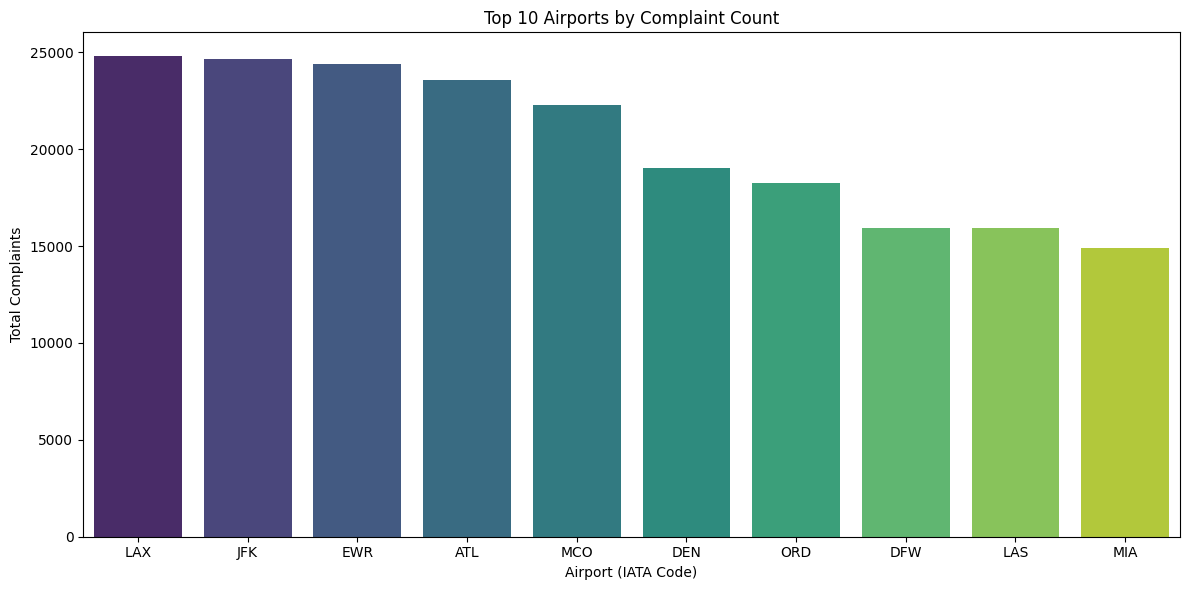

In [21]:
# Aggregate total complaints per airport
airport_totals = (
    complaints_by_airport.groupby("airport")["count"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
sns.barplot(x=airport_totals.index, y=airport_totals.values, palette="viridis")
plt.title("Top 10 Airports by Complaint Count")
plt.xlabel("Airport (IATA Code)")
plt.ylabel("Total Complaints")
plt.tight_layout()
plt.show()

## Visualization 3 – Heatmap of Complaints vs. Airports

- **Data Source:** `complaints-by-category.csv`
- **Goal:** Visualize intensity patterns by mapping complaint categories (rows) against airports (columns) to identify hot spots.


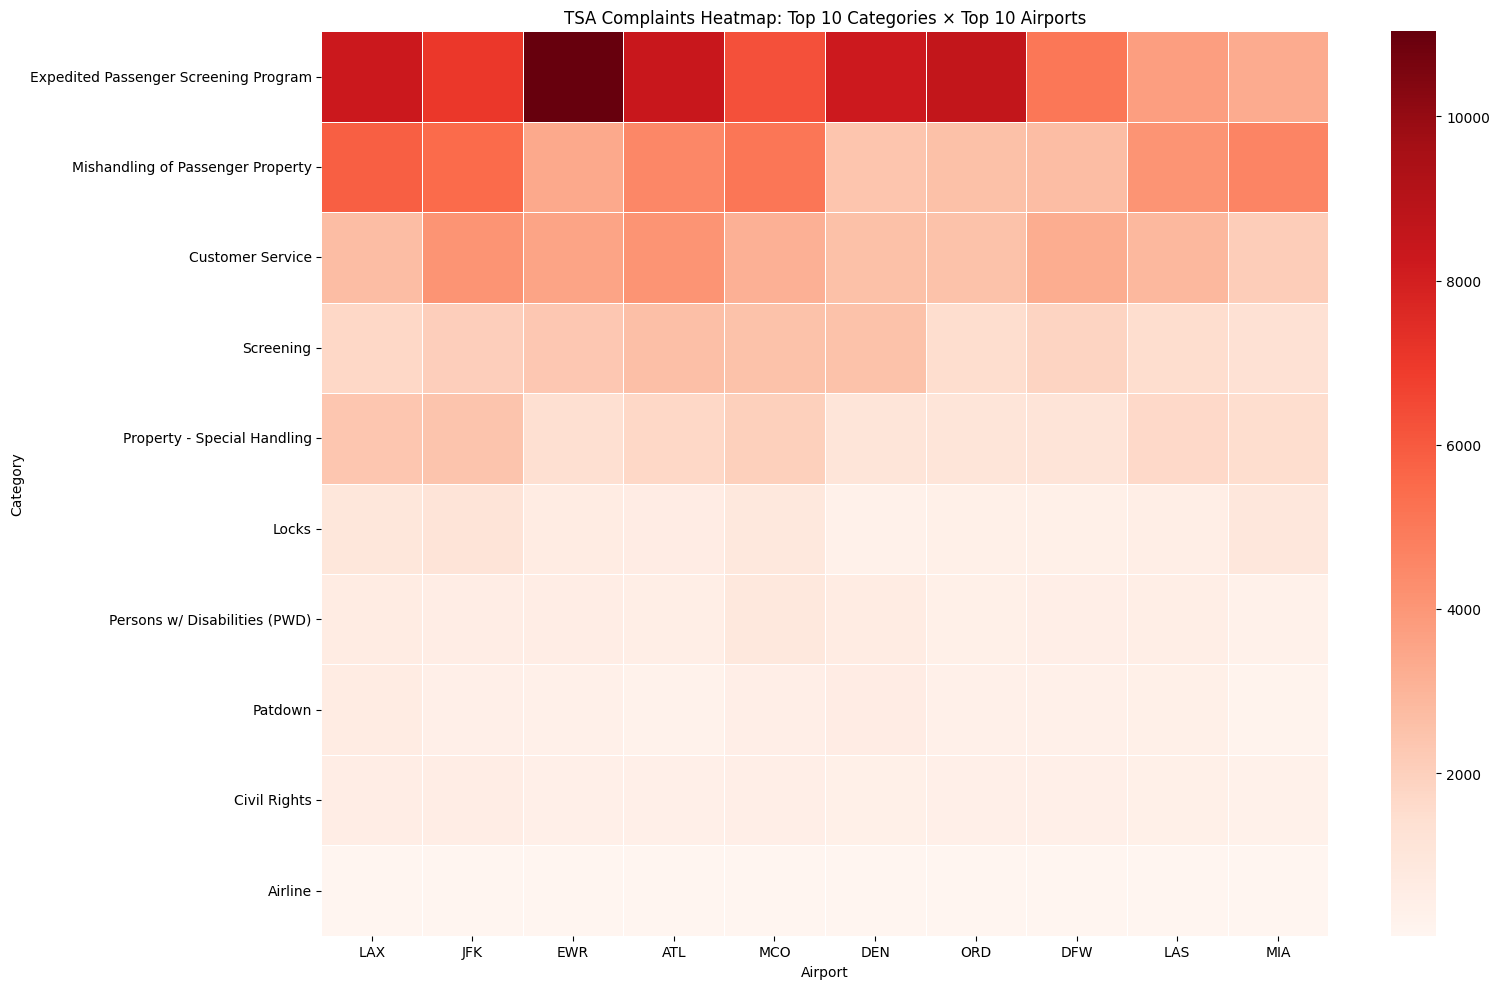

In [22]:
# ---- 1. Find top 10 airports ----
airport_totals = (
    iata_complaints_by_category_icao.groupby("airport")["count"]
    .sum()
    .sort_values(ascending=False)
)

# We have to use the top 10 because smaller region airport only contribute a small amount of data

top_10_airports = airport_totals.head(10).index

# There are too many categories to visualize and most are 0 even for major airports like JFK, so we'll only take the top 10 categories.

# ---- 2. Find top 10 categories ----
category_totals = (
    iata_complaints_by_category_icao.groupby("category")["count"]
    .sum()
    .sort_values(ascending=False)
)

top_10_categories = category_totals.head(10).index

# ---- 3. Filter original data to top airports & top categories ----
top_data = iata_complaints_by_category_icao[
    (iata_complaints_by_category_icao["airport"].isin(top_10_airports))
    & (iata_complaints_by_category_icao["category"].isin(top_10_categories))
]

# ---- 4. Create heatmap matrix ----
heatmap_data = (
    top_data.groupby(["category", "airport"])["count"]
    .sum()
    .unstack(fill_value=0)
    .reindex(index=top_10_categories, columns=top_10_airports)
)

plt.figure(figsize=(16, 10))
sns.heatmap(heatmap_data, cmap="Reds", linewidths=0.5)
plt.title("TSA Complaints Heatmap: Top 10 Categories × Top 10 Airports")
plt.xlabel("Airport")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

## Visualization 4 – Boxplot of Top Sub-Complaint Category

- **Data Source:** `complaints-by-subcategory.csv`
- **Goal:** Display the distribution of counts for the most-frequent sub-complaint category, including outliers.


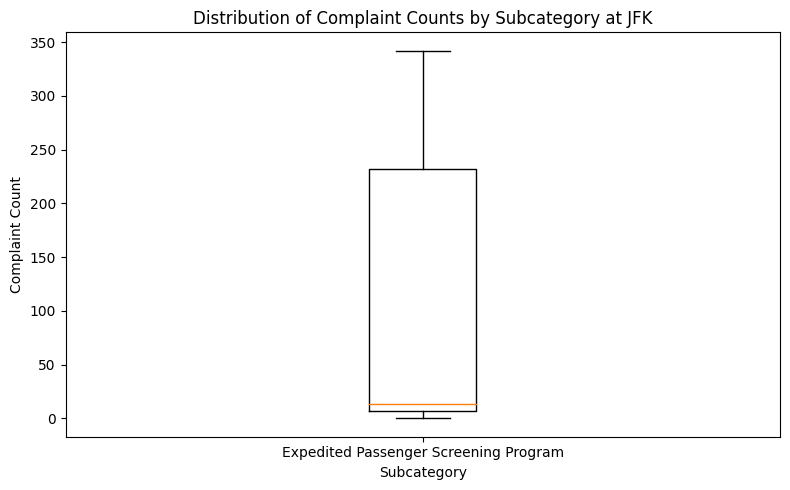

In [23]:
# Reassign to new variable to avoid modifying the original
df_sub = complaints_by_subcategory

# Filter for JFK only, as it has a high complaint count
df_jfk = df_sub[df_sub["airport"] == "JFK"]

# Filter for each subcategory of interest
subcats = [
    "Expedited Passenger Screening Program",
    # We had more here but the major category was the expedited screening so we will just use that one for clarity
]


data = []
labels = []

for sub in subcats:
    counts = df_jfk[df_jfk["subcategory"] == sub]["count"]
    if not counts.empty:
        data.append(counts)
        labels.append(sub)

plt.figure(figsize=(8, 5))

# Multiple boxplots on same chart
plt.boxplot(data, vert=True, labels=labels, showfliers=True)

plt.title("Distribution of Complaint Counts by Subcategory at JFK")
plt.ylabel("Complaint Count")
plt.xlabel("Subcategory")

plt.tight_layout()
plt.show()

## Visualization 5 – Bubble Chart of Top 10 Complaint Categories

- **Data Source:** `complaints-by-subcategory.csv`
- **Goal:** Compare the scale of major complaint categories using bubble size to reflect complaint volume.


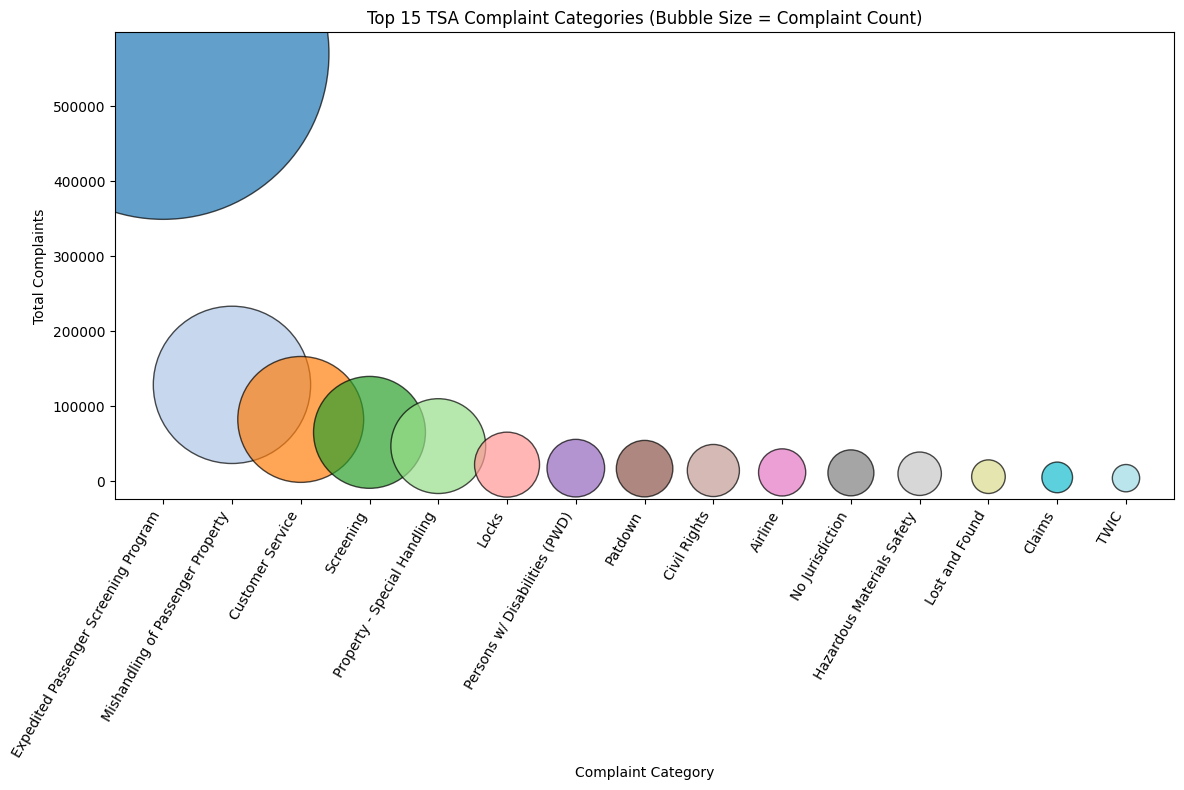

In [24]:
import matplotlib.pyplot as plt
import numpy as np

# Get the top 15 categories
top_15_categories = (
    iata_complaints_by_category_icao.groupby("category")["count"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

# Create a color list—one color per category
colors = plt.cm.tab20(np.linspace(0, 1, len(top_15_categories)))

plt.figure(figsize=(12, 8))
# Create bubble chart
plt.scatter(
    x=top_15_categories["category"],  # x-axis: categories
    y=top_15_categories["count"], # y-axis: total complaints
    s=top_15_categories["count"] / 10,  # scale bubble size
    alpha=0.7,
    color=colors,  # assign colors
    edgecolors="k",
)

# Customize plot
plt.xticks(rotation=60, ha="right")
plt.title("Top 15 TSA Complaint Categories (Bubble Size = Complaint Count)")
plt.xlabel("Complaint Category")
plt.ylabel("Total Complaints")
plt.tight_layout()
plt.show()

## Visualization 6 – Line Chart of TSA Complaints Over Time

- **Data Source:** `complaints-by-subcategory.csv`
- **Goal:** Plot complaint counts by month or year to reveal upward or downward trends in TSA complaints.


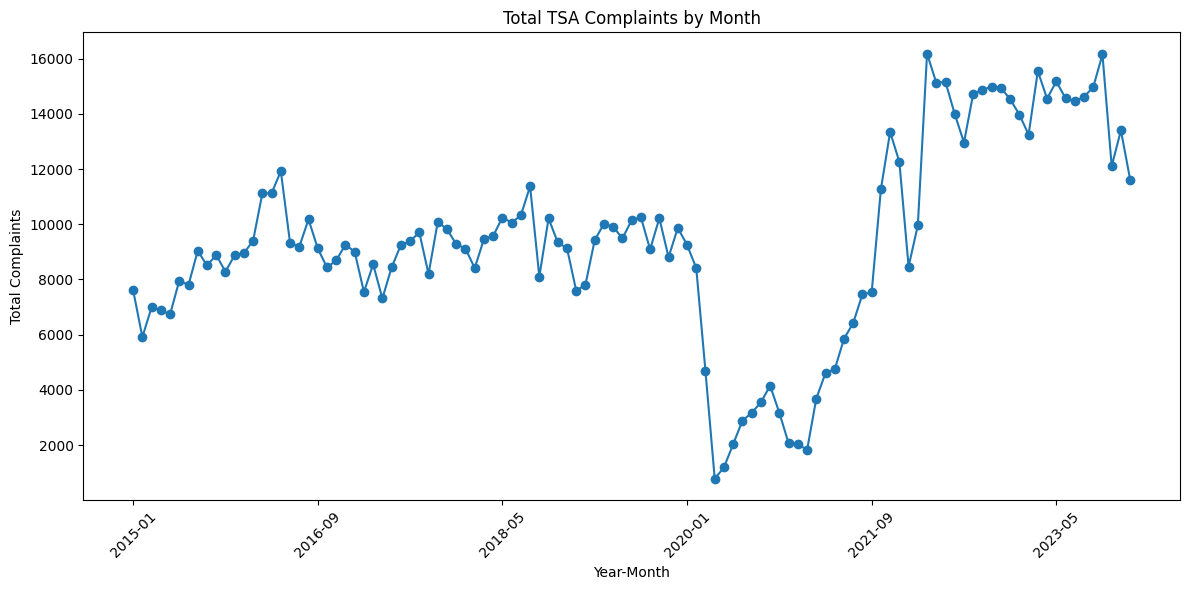

In [25]:
# Time Series Line Plot of Total Complaints by Month
plt.figure(figsize=(12, 6))
# Track complaints over time
complaints_by_subcategory.groupby("year_month")["count"].sum().plot( 
    kind="line", marker="o"
)
# Add gridlines for better readability
plt.title("Total TSA Complaints by Month")
plt.xlabel("Year-Month")
plt.ylabel("Total Complaints")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()